DIGITAL SIGNAL PROCESSING
WEEK 3 – LAB 1B
Convolution, Correlation and Difference Equations

Name:IBRAHIM KELVIN SHIJA

Registration Number:240242495885

Date:23/11/2026


In [1]:
import numpy as np
import time

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y

# Test sequences
x = [1, 2, 3, 1]
h = [1, 1, 1]

# Convolution using our function
y_manual = conv(x, h)

# Convolution using NumPy
y_numpy = np.convolve(x, h)

print("Manual convolution:", y_manual)
print("NumPy convolution:", y_numpy)

Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]


In [2]:
# Generate random sequences
rng = np.random.default_rng(0)

x_random = rng.standard_normal(2000)
h_random = rng.standard_normal(2000)

# Measure manual convolution time
start = time.perf_counter()
y_manual = conv(x_random, h_random)
manual_time = time.perf_counter() - start

# Measure NumPy convolution time
start = time.perf_counter()
y_numpy = np.convolve(x_random, h_random)
numpy_time = time.perf_counter() - start

# Display results
print("Manual convolution time:", manual_time, "seconds")
print("NumPy convolution time:", numpy_time, "seconds")
print("Results agree:", np.allclose(y_manual, y_numpy))

Manual convolution time: 3.1573751920004725 seconds
NumPy convolution time: 0.0021995580000293558 seconds
Results agree: True


NumPy convolution was significantly faster than the manually implemented convolution. Both methods produced identical results, but NumPy completed the operation in approximately 0.0022 seconds, compared to 3.1574 seconds for the manual implementation.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

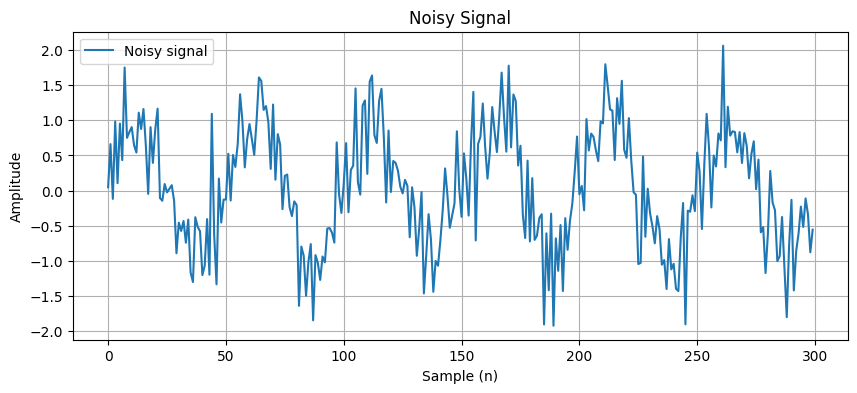

In [5]:
# Generate a noisy signal
n = np.arange(300)

w = np.random.normal(0, 1, 300)

x = np.sin(2 * np.pi * n / 50) + 0.5 * w

# Plot the noisy signal
plt.figure(figsize=(10, 4))
plt.plot(n, x, label="Noisy signal")

plt.title("Noisy Signal")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

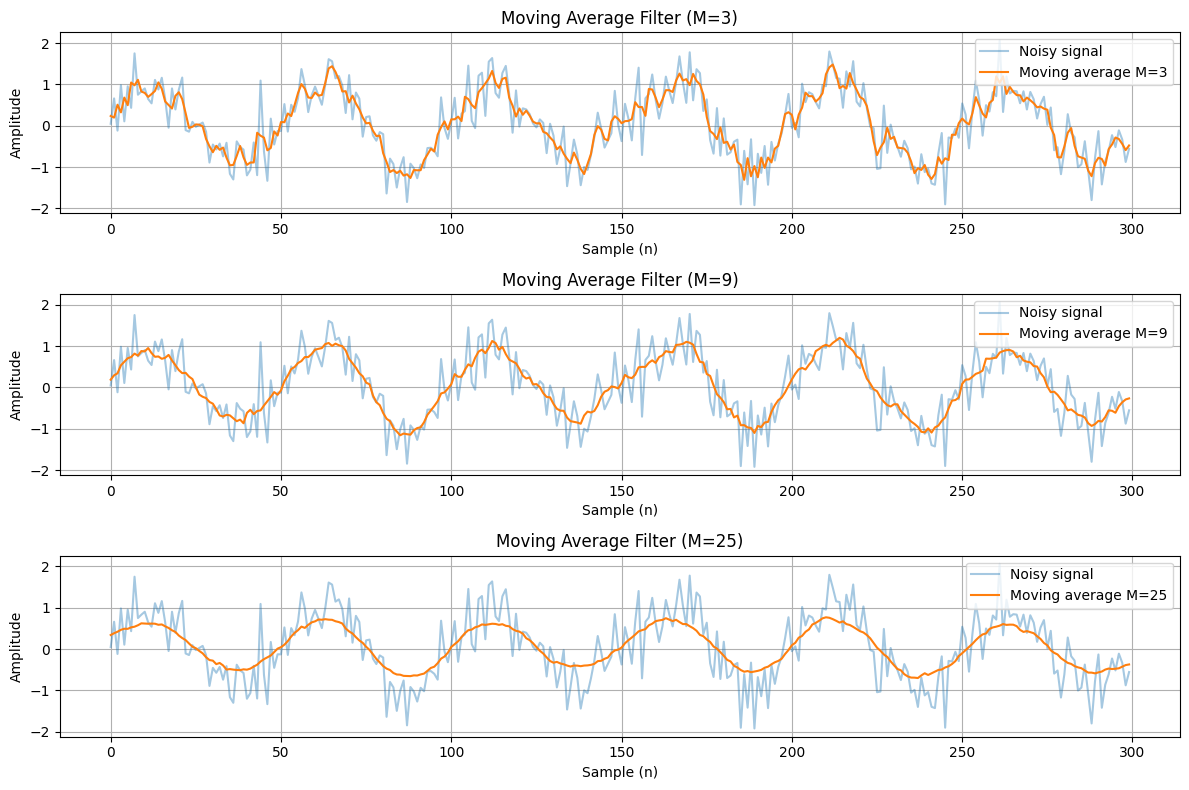

In [6]:
# Moving average filters
M_values = [3, 9, 25]

plt.figure(figsize=(12, 8))

for i, M in enumerate(M_values, 1):
    h = np.ones(M) / M

    y = np.convolve(x, h, mode="same")

    plt.subplot(3, 1, i)
    plt.plot(n, x, alpha=0.4, label="Noisy signal")
    plt.plot(n, y, label=f"Moving average M={M}")

    plt.title(f"Moving Average Filter (M={M})")
    plt.xlabel("Sample (n)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()

The moving-average filters reduced the noise in the original signal. The filter with M=3 provided slight smoothing while preserving most of the original signal shape. The filter with M=9 produced greater noise reduction. The filter with M=25 provided stronger smoothing but also caused more distortion and loss of signal details.

Increasing the moving-average filter length improves noise reduction, but it also increases signal distortion. Therefore, an appropriate filter length should be selected to balance noise reduction and signal preservation.

In [7]:
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Test time invariance
    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


Among the three tested systems, only the moving-average system is Linear Time-Invariant (LTI). The \(x^2\) system is nonlinear, while the \(n x(n)\) system is time-varying.

True delay: 37 samples
Estimated delay: 37 samples


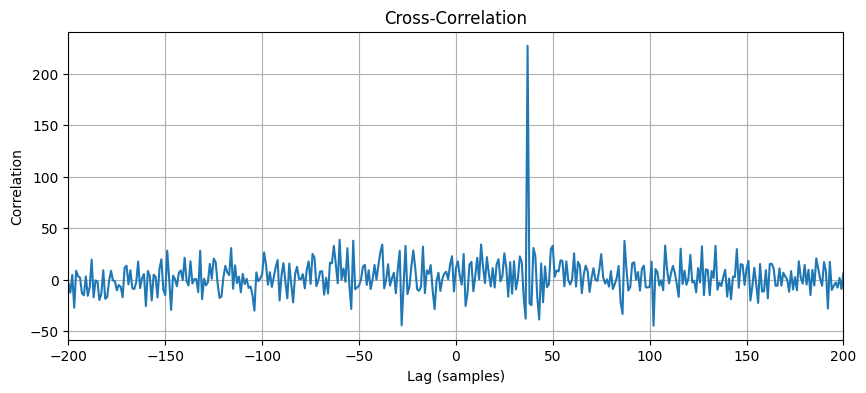

In [8]:
# Generate transmitted signal
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

true_delay = 37

# Generate received signal with delay and noise
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]
y = y + 0.5*rng.standard_normal(500)

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")

# Estimate delay
estimated_delay = lags[np.argmax(r)]

print("True delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")

# Plot cross-correlation
plt.figure(figsize=(10, 4))
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.title("Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

**Observation:**

The cross-correlation function successfully estimated the delay as 37 samples, which matches the actual delay of 37 samples. The large peak in the cross-correlation plot occurs at lag 37, indicating the estimated time delay between the transmitted and received signals.

In [9]:
noise_levels = [0.5, 1, 2, 4]

for noise_std in noise_levels:
    rng = np.random.default_rng(1)

    x = rng.standard_normal(500)

    y = np.concatenate([np.zeros(37), 0.6*x])[:500]
    y = y + noise_std * rng.standard_normal(500)

    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")

    estimated_delay = lags[np.argmax(r)]

    print("Noise:", noise_std,
          "| Estimated delay:", estimated_delay, "samples")

Noise: 0.5 | Estimated delay: 37 samples
Noise: 1 | Estimated delay: 37 samples
Noise: 2 | Estimated delay: 37 samples
Noise: 4 | Estimated delay: 87 samples


**Observation:**

The estimated delay remained accurate at 37 samples when the noise standard deviation was 0.5, 1, and 2. However, when the noise standard deviation increased to 4, the estimated delay changed to 87 samples. This indicates that excessive noise can affect the accuracy of cross-correlation delay estimation.

### Distance Calculation Using the Estimated Time Delay

**Given:**

- Speed of sound, \(v = 343\text{ m/s}\)
- Sampling frequency, \(f_s = 1000\text{ Hz}\)
- Estimated delay, \(N = 37\text{ samples}\)

**Step 1: Calculate the time delay**

The time delay is calculated using:

\[
t = \frac{N}{f_s}
\]

Substituting the given values:

\[
t = \frac{37}{1000}
\]

\[
t = 0.037\text{ seconds}
\]

**Step 2: Calculate the distance**

The distance travelled by the sound pulse is calculated using:

\[
d = v \times t
\]

Substituting the values:

\[
d = 343 \times 0.037
\]

\[
\boxed{d = 12.691\text{ metres}}
\]

**Conclusion:**

The estimated time delay of 37 samples corresponds to a time delay of 0.037 seconds. Using the speed of sound of 343 m/s, the calculated distance travelled by the sound pulse is **12.691 metres**, assuming one-way propagation.

## Task 3.5 — Difference Equation
### Step 1: Impulse Response Using Direct Recursion

In [10]:
# Generate an impulse signal
impulse = np.zeros(10)
impulse[0] = 1

# Initialize output
h = np.zeros(10)

# Calculate impulse response using direct recursion
for n in range(10):

    x_n = impulse[n]
    x_prev = impulse[n-1] if n >= 1 else 0

    y_prev1 = h[n-1] if n >= 1 else 0
    y_prev2 = h[n-2] if n >= 2 else 0

    h[n] = x_n + x_prev + 0.75*y_prev1 - 0.125*y_prev2

print("Impulse response using direct recursion:")
print(h)

Impulse response using direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [11]:
# Calculate impulse response using signal.lfilter()
h_lfilter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Impulse response using lfilter:")
print(h_lfilter)

# Compare both methods
print("Results match:", np.allclose(h, h_lfilter))

Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True


In [12]:
# Generate sample indices
n = np.arange(10)

# Calculate impulse response using the closed-form expression
h_closed = 6*(0.5**n) - 5*(0.25**n)

print("Impulse response using closed-form expression:")
print(h_closed)

# Compare all three methods
print("Direct recursion and closed-form match:",
      np.allclose(h, h_closed))

print("lfilter and closed-form match:",
      np.allclose(h_lfilter, h_closed))

Impulse response using closed-form expression:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Direct recursion and closed-form match: True
lfilter and closed-form match: True


**Observation:**

The impulse responses obtained using direct recursion, `signal.lfilter()`, and the closed-form expression are identical. Both comparison tests returned `True`, confirming that all three methods produce consistent results for the given difference equation.

**Conclusion:**

The direct recursion method and the `signal.lfilter()` function correctly implement the given difference equation. The closed-form expression also verifies the calculated impulse response.

Final value of step response: 5.333333333333323
Theoretical H(1): 5.333333333333333


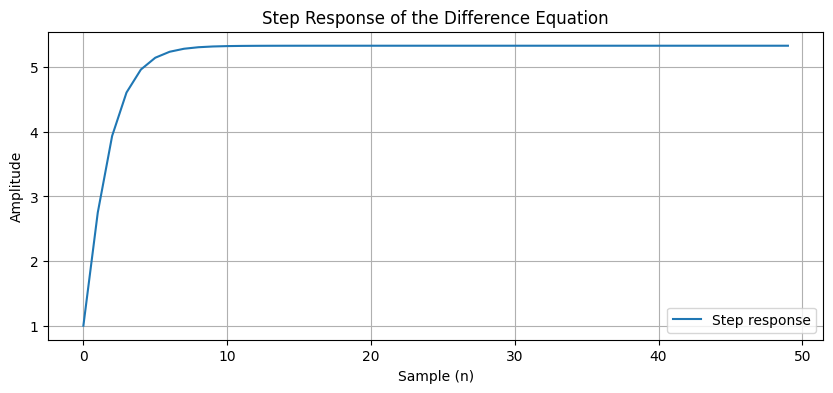

In [13]:
# Generate a unit step signal
step = np.ones(50)

# Calculate step response
y_step = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    step
)

# Display final value
print("Final value of step response:", y_step[-1])

# Calculate theoretical DC gain H(1)
b = [1, 1]
a = [1, -0.75, 0.125]

H1 = sum(b) / sum(a)

print("Theoretical H(1):", H1)

# Plot step response
plt.figure(figsize=(10, 4))
plt.plot(y_step, label="Step response")
plt.title("Step Response of the Difference Equation")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

**Observation:**

The step response increases gradually and eventually reaches a steady-state value of approximately 5.333. The theoretical DC gain, calculated using \(H(1)=\frac{\sum b}{\sum a}\), is also approximately 5.333.

**Conclusion:**

The final value of the step response agrees with the theoretical DC gain. This confirms the correctness of the step response calculation using `signal.lfilter()`.

### Analysis Question 1

**Why is `np.convolve` so much faster than your double loop? What is the number of multiplications for lengths L and M?**

`np.convolve()` is much faster because it uses an optimized implementation within NumPy, whereas the manual double-loop method performs multiplication and addition operations sequentially using Python loops.

For an input signal of length L and an impulse response of length M, the number of multiplications required for direct convolution is:

\[
\text{Number of multiplications}=L\times M
\]

For our experiment:

\[
L=2000,\quad M=2000
\]

\[
2000\times2000=4,000,000
\]

Therefore, 4 million multiplications are required.

The manual convolution took approximately 3.157 seconds, while `np.convolve()` took approximately 0.0022 seconds. This demonstrates the efficiency of NumPy's optimized implementation.

### Analysis Question 2

**Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?**

Only the moving average system is Linear Time-Invariant (LTI).

- The system \(T(x)=x^2\) is nonlinear but time-invariant because squaring the input does not satisfy the linearity property.
- The system \(T(x)=nx(n)\) is linear but time-varying because its output depends on the sample index \(n\).
- The moving average system is both linear and time-invariant because it uses a fixed combination of input samples.

Yes, these properties could have been predicted without running the code by applying the definitions of linearity and time invariance mathematically. The numerical tests in Task 3.3 were used to verify the predictions.

### Analysis Question 3

**Give two engineering applications of cross-correlation in Tanzania.**

**1. Locating leaks in water pipes**

Cross-correlation can be used to detect and locate leaks in water distribution pipelines. Sensors placed at different points along a pipe collect sound or vibration signals. By comparing these signals and estimating their time delay, engineers can determine the approximate location of a leak.

**2. GPS signal synchronization**

Cross-correlation is used in GPS receivers to compare incoming satellite signals with locally generated reference signals. The correlation peak helps determine the signal delay, which is used to estimate the distance between the satellite and the receiver.

These applications demonstrate how cross-correlation can support water infrastructure monitoring and satellite-based positioning in Tanzania.

### Analysis Question 4

**Is the system in Task 3.5 FIR or IIR? Is it stable? Justify from the impulse response.**

The system in Task 3.5 is an **Infinite Impulse Response (IIR)** system because its difference equation contains previous output terms, \(y(n-1)\) and \(y(n-2)\), which create feedback.

The system is **stable** because its impulse response decreases as the sample number increases and approaches zero. The sum of the absolute values of its impulse response is finite, satisfying the BIBO stability condition.

Therefore, the given system is a stable IIR system.

## Checkpoint 3
### Task 3.3 — Linearity and Time-Invariance Results

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True

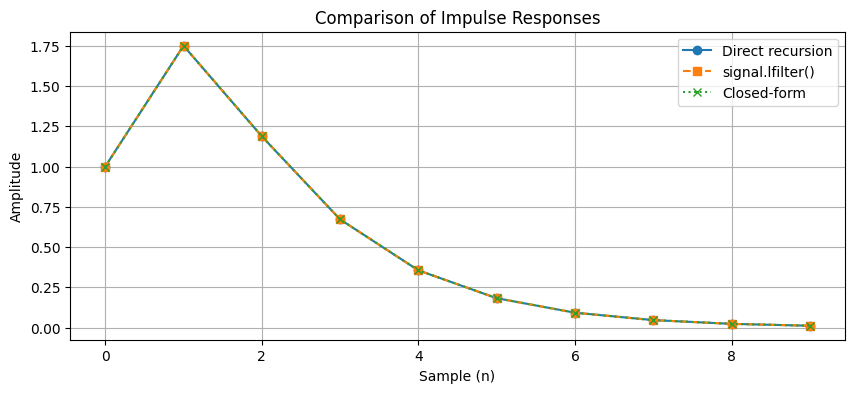

In [14]:
n = np.arange(10)

plt.figure(figsize=(10, 4))
plt.plot(n, h, "o-", label="Direct recursion")
plt.plot(n, h_lfilter, "s--", label="signal.lfilter()")
plt.plot(n, h_closed, "x:", label="Closed-form")

plt.title("Comparison of Impulse Responses")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

**Observation:**

The three impulse responses overlap completely, showing that direct recursion, `signal.lfilter()`, and the closed-form expression produce identical results.

**Conclusion:**

The results confirm that the difference equation has been implemented correctly using all three methods.